# Ancient Environmental Metagenomics (AEMG01)
## Day 1 · Notebook 0: Setting up Google Colab, Google Drive and the course data

<a href="https://colab.research.google.com/github/NikolayOskolkov/AncientEnvironmentalMetagenomics/blob/main/notebooks/Day1_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Run this notebook once, at the very start of the course.** It prepares everything that the following practicals (`Day1_QC.ipynb`, `Day2_...`, …) rely on.

By the end of this notebook you will have:

1. a working **conda / mamba** installation inside Google Colab,
2. your **Google Drive mounted** so that results survive when the Colab machine is switched off,
3. a **shortcut** to the instructor's shared course folder (raw data, databases, scripts) in your own Drive,
4. a copy of the **course GitHub repository** in your Drive,
5. the **10 simulated ancient metagenomic samples** copied to your own `01_DATA` folder,
6. a first look at the data: what a FASTQ file is, how many reads we have and how long they are.

---
## 0. How Google Colab works (read this first)

Google Colab gives you a **temporary Linux virtual machine** in the cloud (typically 2 CPU cores, ~12 GB RAM and ~100 GB of local disk on the free tier) with a Jupyter notebook in front of it. Three things are important to understand:

| Concept | What it means for us |
|---|---|
| **The machine is temporary** | When you close the browser tab for a while or the session times out (~90 min idle, max ~12 h), the machine is deleted together with *everything installed on it* and everything written to `/content` (except your mounted Drive). This is why **every notebook in this course starts by re-installing conda and the software**. |
| **Google Drive is permanent** | We mount your Google Drive at `/content/drive/MyDrive`. Everything we write there (results, reports, BAM files) is kept between days. |
| **Three kinds of cells** | `Python` cells (default), shell commands prefixed with `!` (one line, runs in a throw-away shell), and whole-cell shell scripts starting with `%%bash` (the entire cell is a bash script). We use `%%bash` for most bioinformatics commands, exactly as you would type them in a terminal. |

> 💡 **Important difference to a normal terminal:** each `!` line and each `%%bash` cell starts a *new* shell. A `cd` or a variable defined in one cell is **forgotten** in the next one. That is why every `%%bash` cell in this course begins with `cd $WORKDIR`. Variables that must be shared between cells (paths, number of threads) are stored as **environment variables** from Python with `os.environ[...]`, which all later shells inherit.

> 💡 You can also open a real terminal: click the **Terminal** icon in the bottom-left corner of Colab. Everything in this notebook can be typed there too.

Run cells with **Shift + Enter**. Run them **in order**, top to bottom.

---
## 1. Install conda (mamba) in Colab

Bioinformatics software is most easily installed from the [Bioconda](https://bioconda.github.io/) channel with the **conda** package manager. Colab does not ship with conda, so we install it with the small helper package [`condacolab`](https://github.com/conda-incubator/condacolab), which puts a [Miniforge](https://github.com/conda-forge/miniforge) installation (conda + the faster drop-in replacement **mamba**) into `/usr/local` so that all installed programs are immediately on the `PATH`.

What the next cell does, line by line:

* `!pip install -q condacolab` – installs the helper from PyPI (`-q` = quiet).
* `import condacolab` – loads it into Python.
* `condacolab.install()` – downloads and installs Miniforge, then **automatically restarts the Python kernel**.

⚠️ **Expected behaviour:** after ~1 minute you will see a message like *"Your session crashed for an unknown reason"* or *"Restarting kernel"*. **This is normal** – the kernel must restart to pick up the new Python. Simply continue with the next cell. Do **not** click *Disconnect and delete runtime*, that would remove conda again.

In [1]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:13
🔁 Restarting kernel...


After the restart, check that conda is working. `condacolab.check()` raises an error if something went wrong; `mamba --version` prints the versions of mamba and conda.

In [1]:
import condacolab
condacolab.check()
!mamba --version


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

✨🍰✨ Everything looks OK!
2.5.0


### 1.1 Install the software needed in this notebook

Today we only need one extra tool in this notebook: [**SeqKit**](https://bioinf.shenwei.me/seqkit/), a very fast toolkit for FASTA/FASTQ files that we use to compute read statistics.

`mamba install` arguments explained:

* `-y` – answer *yes* to the confirmation question (cells cannot be interactive),
* `-q` – quiet output,
* `-c conda-forge -c bioconda` – the *channels* (repositories) to search, in priority order. Bioconda packages depend on conda-forge, so conda-forge must come first,
* `seqkit` – the package to install.

In [2]:
!mamba install -y -q -c conda-forge -c bioconda seqkit
!seqkit version

seqkit v2.14.0


---
## 2. Mount your Google Drive

Mounting means making your Google Drive visible as an ordinary folder on the Colab machine. After running the cell you will be asked to log in with your Google account and to **allow** Colab to access your Drive. Your Drive will then appear at `/content/drive/MyDrive`.

* `from google.colab import drive` – loads the Colab helper for Google Drive,
* `drive.mount('/content/drive')` – mounts it at that path.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!ls /content/drive/MyDrive | head -20

9781041109839_first_proofs_au.pdf
AncientEnvironmentalMetagenomics
BiodivFuture
Colab Notebooks
GWAS
Single_Cell_Data_Analysis
Zoom


---
## 3. Add the shared course folder to your Drive (one-time, done in the browser)

All course input data – raw reads, reference genomes, pre-built databases and helper scripts – live in a shared Google Drive folder:

👉 **[https://drive.google.com/drive/folders/13KmgouAO6vCYb0DI74Uk1DvM3_myRxix?usp=sharing](https://drive.google.com/drive/folders/13KmgouAO6vCYb0DI74Uk1DvM3_myRxix?usp=sharing)**

Colab can only see folders that are inside **My Drive**; folders in *Shared with me* are **not** visible after mounting. The simplest and fastest solution is to add a **shortcut** to the shared folder in your own Drive. A shortcut does **not** use any of your storage quota, and the large databases do not have to be copied.

**Steps:**

1. Open the link above in a new browser tab.
2. At the top, click the folder name ▸ **Organize** ▸ **Add shortcut** (in older Drive versions: right-click the folder ▸ *Add shortcut to Drive*).
3. Choose **My Drive** as the location and click **Add**.
4. Come back here and run the next cell.

The shortcut will appear inside `/content/drive/MyDrive/` under the name of the shared folder. The cell below **finds it automatically**: it searches My Drive for a folder that contains `data/SAMPLES.txt`, which is how the course folder is organised:

```
<shared folder>/
├── data/            ← 10 simulated samples (*.fastq.gz) + SAMPLES.txt
├── Databases/       ← hg38 Bowtie2 index, KrakenUniq, Kraken2, sourmash, …
└── scripts/         ← helper scripts used during the week
```

> If the automatic search fails (e.g. you put the shortcut into a sub-folder), set `SHARE` manually, e.g. `SHARE = "/content/drive/MyDrive/Share"`.

In [8]:
import glob, os, json

MYDRIVE = "/content/drive/MyDrive"
SHARE = None   # <- set manually here if the automatic search below fails

if SHARE is None:
    hits = (glob.glob(f"{MYDRIVE}/*/data/SAMPLES.txt") +
            glob.glob(f"{MYDRIVE}/*/*/data/SAMPLES.txt"))
    if hits:
        SHARE = os.path.dirname(os.path.dirname(hits[0]))

if SHARE and os.path.isdir(SHARE):
    print("✅ Shared course folder found at:", SHARE)
    print("   Content:", sorted(os.listdir(SHARE)))
else:
    print("❌ Shared folder not found. Did you add the shortcut to *My Drive* (Section 3)?")

✅ Shared course folder found at: /content/drive/MyDrive/AncientEnvironmentalMetagenomics
   Content: ['Day1_QC.ipynb', 'Day1_setup.ipynb', 'KrakenUniq_DB', 'data', 'hg38', 'minikraken2_v2_8GB_201904_UPDATE']


---
## 4. Get the course repository from GitHub

The course material (exercise texts, images, helper files for the practicals) is kept in a GitHub repository. We *clone* it into your Drive, so it is preserved for the whole week.

* `cd /content/drive/MyDrive` – go to the root of your Drive,
* `git clone <url>` – download a full copy of the repository into a new folder `AncientEnvironmentalMetagenomics`,
* `git pull` – if the folder already exists (e.g. you re-run this cell), fetch the latest changes instead. **Re-run this every morning** to get any updates the instructor has made.

The `if [ -d … ]` construction is a bash *if-statement*: `-d` tests whether a directory exists.

In [9]:
%%bash
cd /content/drive/MyDrive/AncientEnvironmentalMetagenomics
if [ -d AncientEnvironmentalMetagenomics/.git ]; then
    echo "Repository already exists – updating it with git pull"
    cd AncientEnvironmentalMetagenomics && git pull
else
    git clone https://github.com/NikolayOskolkov/AncientEnvironmentalMetagenomics
fi

Cloning into 'AncientEnvironmentalMetagenomics'...
Updating files: 100% (68/68), done.


Now we define the **paths used throughout the course** and store them:

* as **environment variables** (`os.environ`), so that every `%%bash` cell can use `$WORKDIR`, `$SHARE` and `$THREADS`;
* in a small file **`course_paths.json`** inside your working folder, so that the notebooks for Days 1–5 can find the shared folder again without searching.

`THREADS` is the number of CPU cores of the Colab machine (`os.cpu_count()`, usually 2). We pass it to every multi-threaded tool instead of a hard-coded number.

In [10]:
WORKDIR = f"{MYDRIVE}/AncientEnvironmentalMetagenomics"
THREADS = os.cpu_count()

os.environ["SHARE"] = SHARE
os.environ["WORKDIR"] = WORKDIR
os.environ["THREADS"] = str(THREADS)

json.dump({"SHARE": SHARE, "WORKDIR": WORKDIR},
          open(f"{WORKDIR}/course_paths.json", "w"), indent=2)

os.chdir(WORKDIR)
print("Working directory:", os.getcwd())
print("Shared folder    :", SHARE)
print("CPU threads      :", THREADS)

Working directory: /content/drive/MyDrive/AncientEnvironmentalMetagenomics
Shared folder    : /content/drive/MyDrive/AncientEnvironmentalMetagenomics
CPU threads      : 2


---
## 5. Getting the raw data

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/aMeta.png" width="750"><br><em>The aMeta workflow and the simulated benchmark data set (Pochon et al. 2023).</em></p>

We will use **10 ancient metagenomic samples simulated with [gargammel](https://academic.oup.com/bioinformatics/article/33/4/577/2608651)** from Pochon et al. 2023 (the aMeta paper). gargammel takes real reference genomes and simulates sequencing reads *as if* they came from ancient DNA: the DNA is fragmented into short pieces, **deamination damage** (C→T at the 5′ ends, G→A at the 3′ ends) is added, sequencing adapters and sequencing errors are added, and the ancient reads are mixed with modern "contaminant" reads. Because we know the ground truth (which microbes were put in, and which of them are ancient), simulated data are ideal for learning – we can check whether our analyses recover the truth. The data are publicly available at [https://doi.org/10.17044/scilifelab.21261405](https://doi.org/10.17044/scilifelab.21261405).

For reference, this is how the data were originally downloaded (**do not run – already done** and placed in the shared folder):

```bash
# DO NOT RUN THIS (ALREADY DONE)
wget https://figshare.scilifelab.se/ndownloader/articles/21261405/versions/1 && unzip 1 && rm 1
```

### 5.1 Copy the data to your own `01_DATA` folder

We copy the raw reads and the file `SAMPLES.txt` (a list of sample names, one per line, which we will use in `for` loops all week) into your working folder.

* `mkdir -p 01_DATA` – create the folder; `-p` = no error if it already exists,
* `cp -n` – copy; `-n` (*no-clobber*) skips files that are already there, so the cell is safe to re-run,
* `$SHARE/data/*.fastq.gz` – the `*` wildcard matches all gzipped FASTQ files,
* `ls -lh` – list with human-readable sizes; `du -sh` – total size of the folder.

Copying between two Drive locations can take a few minutes.

In [11]:
%%bash
cd $WORKDIR
mkdir -p 01_DATA

cp -n $SHARE/data/*.fastq.gz 01_DATA/
cp -n $SHARE/data/SAMPLES.txt ./

ls -lh 01_DATA/
du -sh 01_DATA/
echo "Samples listed in SAMPLES.txt:"
cat SAMPLES.txt

total 526M
-rw------- 1 root root 62M Nov 20 15:28 sample10.fastq.gz
-rw------- 1 root root 53M Nov 20 15:28 sample1.fastq.gz
-rw------- 1 root root 43M Nov 20 15:28 sample2.fastq.gz
-rw------- 1 root root 45M Nov 20 15:28 sample3.fastq.gz
-rw------- 1 root root 49M Nov 20 15:28 sample4.fastq.gz
-rw------- 1 root root 51M Nov 20 15:28 sample5.fastq.gz
-rw------- 1 root root 53M Nov 20 15:28 sample6.fastq.gz
-rw------- 1 root root 56M Nov 20 15:28 sample7.fastq.gz
-rw------- 1 root root 58M Nov 20 15:29 sample8.fastq.gz
-rw------- 1 root root 60M Nov 20 15:29 sample9.fastq.gz
526M	01_DATA/
Samples listed in SAMPLES.txt:
sample1
sample2
sample3
sample4
sample5
sample6
sample7
sample8
sample9
sample10


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


<details>
<summary><b>🛟 Plan B – if the shortcut does not work for you (click to expand)</b></summary>

You can download the data folder directly from the public link with [`gdown`](https://github.com/wkentaro/gdown). Note that `gdown --folder` downloads at most 50 files per folder and that Google may temporarily rate-limit very popular files.

```python
!pip install -q gdown
!gdown --folder "https://drive.google.com/drive/folders/13KmgouAO6vCYb0DI74Uk1DvM3_myRxix" -O /content/course_share
```
Then copy `/content/course_share/<folder>/data/*` to `01_DATA/` and set `SHARE` to `/content/course_share/<folder>`. Large databases are better accessed through the shortcut.
</details>

---
## 6. A first look at the data

### 6.1 The FASTQ format

<p align="center">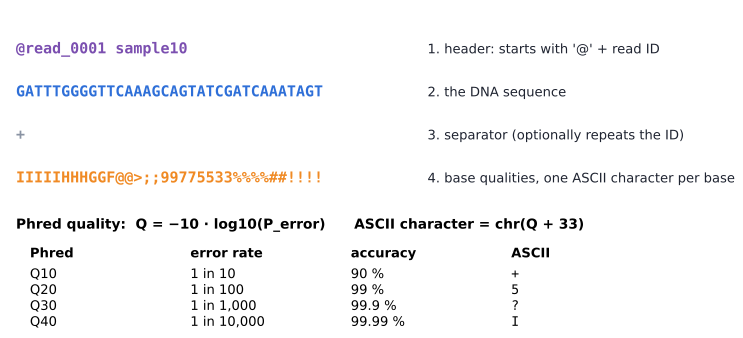</p>

Sequencing machines write reads in **FASTQ** format: **4 lines per read**

1. the read **identifier**, always starting with `@`,
2. the **DNA sequence**,
3. a separator line starting with `+`,
4. the **base qualities**: one character per base. Each character encodes a **Phred score** `Q = −10·log10(P_error)`, written as the ASCII character number `Q + 33`. So `I` (ASCII 73) means Q40 (1 error in 10,000) while `#` (ASCII 35) means Q2 (almost certainly wrong).

Our files are gzip-compressed (`.fastq.gz`). `zcat` decompresses them **on the fly** to the screen without creating an uncompressed copy, and `head` shows only the first 10 lines (`head -n 8` = the first 2 reads). The `|` (*pipe*) sends the output of one command into the input of the next.

In [12]:
%%bash
cd $WORKDIR
zcat 01_DATA/sample1.fastq.gz | head -n 8

@endo_393:+:4746:4786:40e1_0-2/1
CAGGTATACGTGGCATTTTTGTAACCGACGCACACTAAACAGATCGGAAGAGCACACGTCTGAACTCCAGTCACCGATTCGATCTCGTATGCCGTCTTCTGCTTGAGCTGGAGCAGCCGGCCGTT
+
CCCCCDGGGGGGGGGGG1GGGGGGGBGGG/GGGGGGGG>GGGGGGGGGG@GGGGEGGGBGGGGGGGB1GEGGGGGGGGGGGGGGGGGGGGEG=0GGGGGGCGGBGGGGGEGG/CGGG/CGGGGGG
@endo_498:-:6451:6482:31e1_0-2/1
GGGTAATTGTCTTATCCCCCGAAAATTCGGAAGATCGGAAGAGCACACGTCTGAACTCCAGTCACCGATTCGATCTCGTATGCCGTCTTCTGCTTGGATCTGCGATTGTTGATATGATGGCGTTT
+
CBCCCGGGGGGG/GGG;GGGGGGGGDGGGCGGGGGGGGGGG0GGGFGGGGGGGGEEG1GGDG0GGGG=<:G0;FGGGGGGEFGGGGDGGGGG0GGGG8GG@GGCGG.EGG8GGGGGGGGGG>EGG


### 6.2 How many reads do we have?

The original course command counts lines starting with `@`:

```bash
zcat 01_DATA/sample1.fastq.gz | grep -c ^@
```

* `grep -c` – **c**ount the lines that match a pattern,
* `^@` – a *regular expression*: `^` means "start of line", so: lines starting with `@`.

⚠️ **A classic pitfall:** `@` is also a valid **quality character** (Q31)! A quality line that happens to start with `@` is counted as an extra read, so this command can *over-estimate* the number of reads. The robust way is to count all lines and divide by 4 (`wc -l` counts lines; `$(( … ))` is bash arithmetic). Let's compare the two:

In [13]:
%%bash
cd $WORKDIR
echo "grep -c ^@        : $(zcat 01_DATA/sample1.fastq.gz | grep -c ^@)"
echo "lines / 4 (robust): $(( $(zcat 01_DATA/sample1.fastq.gz | wc -l) / 4 ))"

grep -c ^@        : 706418
lines / 4 (robust): 700000


❓ **Question:** How many reads are there in `sample1`? Do the two methods agree? Why could they differ?

### 6.3 Statistics for all samples with SeqKit

`seqkit stats` computes, for every file, the number of reads (`num_seqs`), total bases (`sum_len`) and the min / average / max read length; `-a` (*all*) adds quartiles of read length, N50 and the fraction of bases ≥ Q20 / Q30. `-T` produces a tab-separated table which we read into a **pandas** data frame for nicer display. `-j $THREADS` processes files in parallel.

In [14]:
%%bash
cd $WORKDIR
seqkit stats -a -T -j $THREADS 01_DATA/*.fastq.gz > 01_DATA/seqkit_stats_raw.tsv

processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:  0 / 10 [-----] ETA: 0s
processed files:

In [15]:
import pandas as pd
stats = pd.read_csv("01_DATA/seqkit_stats_raw.tsv", sep="\t")
stats["file"] = stats["file"].str.replace("01_DATA/", "").str.replace(".fastq.gz", "")
stats[["file", "num_seqs", "sum_len", "min_len", "avg_len", "max_len", "Q20(%)", "Q30(%)"]]

,file,num_seqs,sum_len,min_len,avg_len,max_len,Q20(%),Q30(%)
0,sample10,825000,103125000,125,125.0,125,96,93
1,sample1,700000,87500000,125,125.0,125,96,93
2,sample2,575000,71875000,125,125.0,125,96,93
3,sample3,600000,75000000,125,125.0,125,96,93
4,sample4,650000,81250000,125,125.0,125,96,93
5,sample5,675000,84375000,125,125.0,125,96,93
6,sample6,700000,87500000,125,125.0,125,96,93
7,sample7,750000,93750000,125,125.0,125,96,93
8,sample8,775000,96875000,125,125.0,125,96,93
9,sample9,800000,100000000,125,125.0,125,96,93


### 6.4 Read-length distribution

For ancient DNA, **read length is biologically meaningful**: DNA breaks down after death, so authentic ancient molecules are typically only **30–70 bp** long, whereas modern DNA is much longer. Let's plot the raw read lengths for one sample. We read the first 200,000 reads with Python's `gzip` module (every 4th line, starting from line 2, is a sequence).

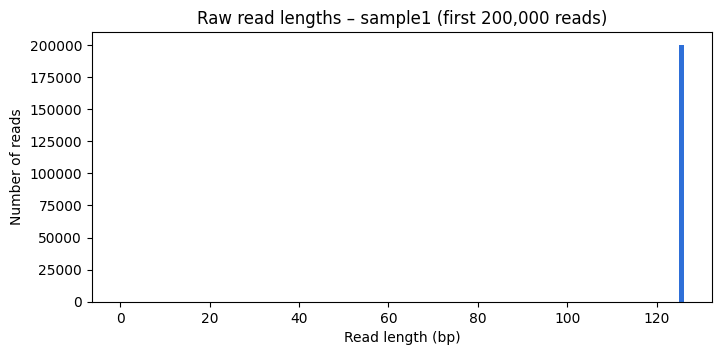

In [16]:
import gzip, numpy as np, matplotlib.pyplot as plt

def read_lengths(path, n=200_000):
    lengths = []
    with gzip.open(path, "rt") as f:
        for i, line in enumerate(f):
            if i % 4 == 1:                      # the sequence line of each record
                lengths.append(len(line.strip()))
                if len(lengths) >= n:
                    break
    return np.array(lengths)

L = read_lengths("01_DATA/sample1.fastq.gz")
plt.figure(figsize=(8, 3.5))
plt.hist(L, bins=range(0, L.max() + 2), color="#2E6FD8")
plt.xlabel("Read length (bp)"); plt.ylabel("Number of reads")
plt.title("Raw read lengths – sample1 (first 200,000 reads)")
plt.show()

❓ **Question:** Do all raw reads have the same length? What does this tell you about whether adapters have already been removed? (Keep this plot in mind – we will plot the length distribution again *after* adapter trimming in `Day1_QC.ipynb`.)

---
## ✅ Checklist before moving on

Run the cell below. If everything is green you are ready for **`Day1_QC.ipynb`**.

In [17]:
checks = {
    "conda/mamba installed"      : os.system("which mamba > /dev/null") == 0,
    "Google Drive mounted"       : os.path.isdir("/content/drive/MyDrive"),
    "shared folder found"        : bool(SHARE) and os.path.isdir(SHARE),
    "course repository cloned"   : os.path.isdir(f"{WORKDIR}/.git"),
    "course_paths.json written"  : os.path.isfile(f"{WORKDIR}/course_paths.json"),
    "10 FASTQ files in 01_DATA"  : len(glob.glob(f"{WORKDIR}/01_DATA/*.fastq.gz")) >= 10,
    "SAMPLES.txt present"        : os.path.isfile(f"{WORKDIR}/SAMPLES.txt"),
}
for k, v in checks.items():
    print(("✅ " if v else "❌ ") + k)

✅ conda/mamba installed
✅ Google Drive mounted
✅ shared folder found
❌ course repository cloned
✅ course_paths.json written
✅ 10 FASTQ files in 01_DATA
✅ SAMPLES.txt present


**What is persistent and what is not?** Everything in `/content/drive/MyDrive/AncientEnvironmentalMetagenomics` (your data copy, the repository, `course_paths.json`) stays in your Drive. Conda and SeqKit disappear when this Colab session ends – that's why each day's notebook re-installs them in its first cells.

In [18]:
!jupyter nbconvert --to html /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day1_setup.ipynb

[NbConvertApp] Converting notebook /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day1_setup.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 410858 bytes to /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day1_setup.html
